<a href="https://colab.research.google.com/github/2004sreedevip/ML-Lab-/blob/main/AML_Assignment(2).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Euclidean Distance Matrix (first 5 samples):
[[0.         1.17621868 0.84560741 1.10368502 0.26013882]
 [1.17621868 0.         0.52337301 0.43399991 1.3864853 ]
 [0.84560741 0.52337301 0.         0.28389113 0.99157157]
 [1.10368502 0.43399991 0.28389113 0.         1.25016028]
 [0.26013882 1.3864853  0.99157157 1.25016028 0.        ]]

K-means Silhouette Score: 0.4599


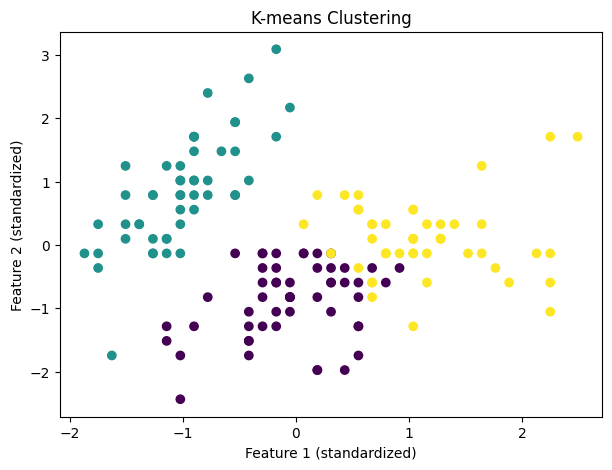

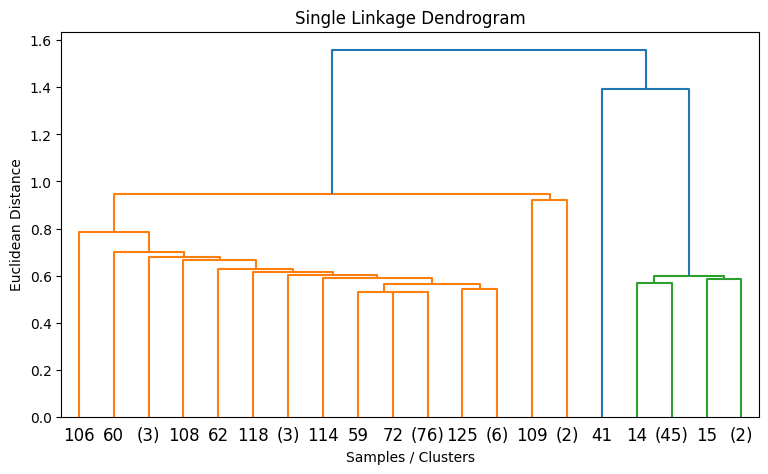


Single Linkage Silhouette Score: 0.5046


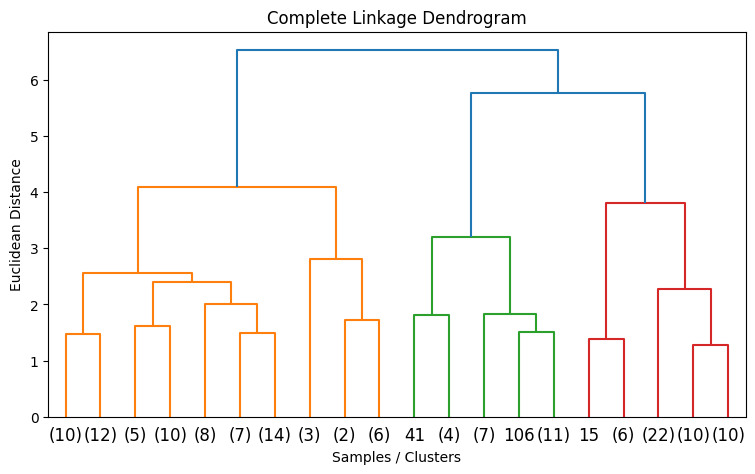


Complete Linkage Silhouette Score: 0.4496


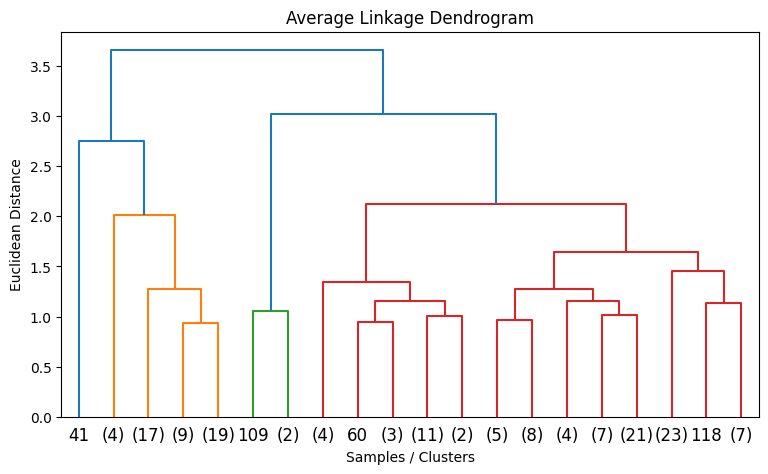


Average Linkage Silhouette Score: 0.4803

Similarity Matrix (first 5 samples):
[[1.         0.45951264 0.54182704 0.47535633 0.79356337]
 [0.45951264 1.         0.65643804 0.69735011 0.41902626]
 [0.54182704 0.65643804 1.         0.77888224 0.50211602]
 [0.47535633 0.69735011 0.77888224 1.         0.44441279]
 [0.79356337 0.41902626 0.50211602 0.44441279 1.        ]]


In [ ]:
#QN-2a

import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.spatial.distance import pdist, squareform

iris = load_iris()
X = iris.data

X_scaled = StandardScaler().fit_transform(X)

distances = pdist(X_scaled[:5], metric='euclidean')
distance_matrix = squareform(distances)

print("Euclidean Distance Matrix (first 5 samples):")
print(distance_matrix)

kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
kmeans_labels = kmeans.fit_predict(X_scaled)

print("\nK-means Silhouette Score:",
      round(silhouette_score(X_scaled, kmeans_labels), 4))

plt.figure(figsize=(7, 5))
plt.scatter(X_scaled[:, 0], X_scaled[:, 1],
            c=kmeans_labels, cmap='viridis')
plt.xlabel("Feature 1 (standardized)")
plt.ylabel("Feature 2 (standardized)")
plt.title("K-means Clustering")
plt.show()

for method in ['single', 'complete', 'average']:
    Z = linkage(X_scaled, method=method, metric='euclidean')

    plt.figure(figsize=(9, 5))
    dendrogram(Z, truncate_mode='lastp', p=20)
    plt.title(f"{method.capitalize()} Linkage Dendrogram")
    plt.xlabel("Samples / Clusters")
    plt.ylabel("Euclidean Distance")
    plt.show()

    model = AgglomerativeClustering(
        n_clusters=3, linkage=method, metric='euclidean'
    )
    labels = model.fit_predict(X_scaled)

    print(f"\n{method.capitalize()} Linkage Silhouette Score:",
          round(silhouette_score(X_scaled, labels), 4))

similarity = 1 / (1 + distance_matrix)

print("\nSimilarity Matrix (first 5 samples):")
print(similarity)


Model: Random Forest (Bagging)
Accuracy: 90.0 %
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.82      0.90      0.86        10
   virginica       0.89      0.80      0.84        10

    accuracy                           0.90        30
   macro avg       0.90      0.90      0.90        30
weighted avg       0.90      0.90      0.90        30


Model: AdaBoost (Boosting)
Accuracy: 93.33 %
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



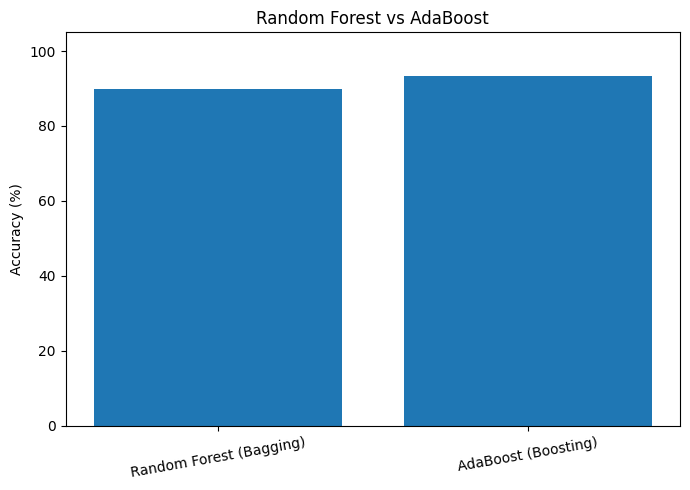

In [ ]:
#Qn-2b

import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.metrics import accuracy_score, classification_report

iris = load_iris()
X = iris.data
y = iris.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

models = {
    "Random Forest (Bagging)": RandomForestClassifier(
        n_estimators=100, random_state=42
    ),
    "AdaBoost (Boosting)": AdaBoostClassifier(
        n_estimators=50, random_state=42
    )
}

results = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    accuracy = accuracy_score(y_test, y_pred)
    results[name] = accuracy * 100

    print("\nModel:", name)
    print("Accuracy:", round(accuracy * 100, 2), "%")
    print(classification_report(
        y_test, y_pred,
        target_names=iris.target_names,
        zero_division=0
    ))

plt.figure(figsize=(7, 5))
plt.bar(results.keys(), results.values())
plt.ylabel("Accuracy (%)")
plt.title("Random Forest vs AdaBoost")
plt.ylim(0, 105)
plt.xticks(rotation=10)
plt.tight_layout()
plt.show()

Cluster Labels:
[1 1 1 1 1 1 1 1 2 1 1 1 1 2 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 2 1 1 2 2 1 1 1 1 1 1 1 0 0 0 0 0 0 0 0 0 0 2 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 2 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0]

Cluster Probabilities (first 5 samples):
[[2.74503381e-011 1.00000000e+000 0.00000000e+000]
 [1.16033052e-007 9.99999884e-001 0.00000000e+000]
 [9.72921434e-009 9.99999990e-001 5.88168010e-278]
 [2.02193473e-007 9.99999798e-001 3.33173699e-141]
 [9.67775891e-012 1.00000000e+000 0.00000000e+000]]

Silhouette Score: 0.4751


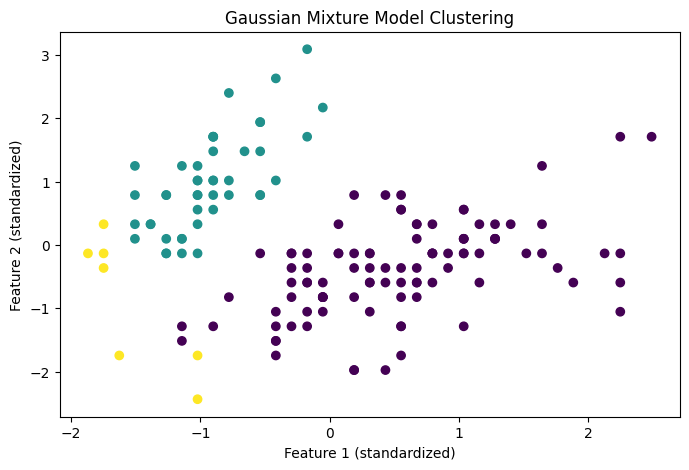

In [ ]:
#Qn-2c

import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score

iris = load_iris()
X = iris.data

X_scaled = StandardScaler().fit_transform(X)

gmm = GaussianMixture(
    n_components=3, random_state=42
)

gmm.fit(X_scaled)
labels = gmm.predict(X_scaled)

print("Cluster Labels:")
print(labels)

print("\nCluster Probabilities (first 5 samples):")
print(gmm.predict_proba(X_scaled[:5]))

print("\nSilhouette Score:",
      round(silhouette_score(X_scaled, labels), 4))

plt.figure(figsize=(8, 5))
plt.scatter(
    X_scaled[:, 0], X_scaled[:, 1],
    c=labels, cmap="viridis"
)
plt.xlabel("Feature 1 (standardized)")
plt.ylabel("Feature 2 (standardized)")
plt.title("Gaussian Mixture Model Clustering")
plt.show()

Original Data Shape: (150, 4)
Reduced Data Shape: (150, 2)
Explained Variance Ratio: [0.72962445 0.22850762]
Total Explained Variance: 95.81 %


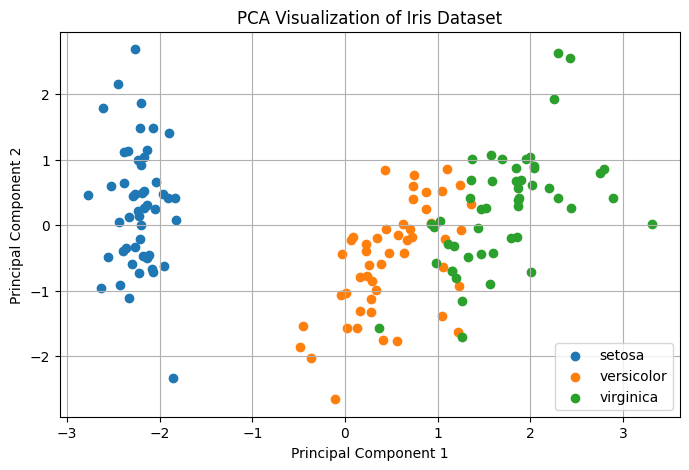

In [ ]:
#Qn-2d

import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

iris = load_iris()
X = iris.data
y = iris.target

X_scaled = StandardScaler().fit_transform(X)

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

print("Original Data Shape:", X.shape)
print("Reduced Data Shape:", X_pca.shape)
print("Explained Variance Ratio:",
      pca.explained_variance_ratio_)
print("Total Explained Variance:",
      round(sum(pca.explained_variance_ratio_) * 100, 2), "%")

plt.figure(figsize=(8, 5))

for i, name in enumerate(iris.target_names):
    plt.scatter(
        X_pca[y == i, 0],
        X_pca[y == i, 1],
        label=name
    )

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA Visualization of Iris Dataset")
plt.legend()
plt.grid(True)
plt.show()